# 05 — Inference: Loss Analysis & Next-Day Prediction
**Goal:** Use our trained model (`models/best_solar_model.joblib`) to solve the last two parts of our project:
1. **Loss Analysis:** Compare **Expected vs Actual** `AC_POWER` during active sunlight (`IRRADIATION >= 0.05`) to find underperforming inverters, daytime outages, and loss factors.
2. **Future Prediction:** Fetch **tomorrow's live weather forecast** from the free Open-Meteo API and predict tomorrow's hourly solar production!


## Part 1: Load Saved Model & Predict Expected Power
> **Why `IRRADIATION >= 0.05`?** At 5:45 AM dawn (`IRRADIATION ≈ 0.0005`), sunlight is too weak to reach an inverter's startup voltage, so `AC_POWER = 0` and dividing near-zero numbers creates meaningless ratios. Filtering to active sunlight (`IRRADIATION >= 0.05`) gives clean, reliable `PERF_RATIO` with **zero `NaN`s**.

In [ ]:
import joblib
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Load our winning model and test dataset
model = joblib.load("../models/best_solar_model.joblib")
test  = pd.read_csv("../data/processed/test.csv", parse_dates=["DATE_TIME"])

active = test[test["IRRADIATION"] >= 0.05].copy().reset_index(drop=True)

features = [
    "IRRADIATION", "MODULE_TEMPERATURE", "AMBIENT_TEMPERATURE", "TEMP_DIFF",
    "relative_humidity_2m", "cloud_cover", "wind_speed_10m", "HOUR_SIN", "HOUR_COS"
]

# Predict expected AC_POWER
active["EXPECTED_AC_POWER"] = np.clip(model.predict(active[features].astype(np.float32)), 1.0, None)

# Production gap: positive LOSS = panel produced LESS than expected
active["LOSS"] = active["EXPECTED_AC_POWER"] - active["AC_POWER"]

# Performance Ratio (Actual / Expected): 1.0 = healthy, < 0.85 = underperforming
active["PERF_RATIO"] = (active["AC_POWER"] / active["EXPECTED_AC_POWER"]).round(3)

print("Active sunlight rows:", len(active), "| Missing PERF_RATIO:", active["PERF_RATIO"].isna().sum())
active[["DATE_TIME", "PLANT_ID", "SOURCE_KEY", "IRRADIATION", "AC_POWER", "EXPECTED_AC_POWER", "LOSS", "PERF_RATIO"]].head(8)


Active sunlight rows: 9922 | Missing PERF_RATIO: 0


,DATE_TIME,PLANT_ID,SOURCE_KEY,IRRADIATION,AC_POWER,EXPECTED_AC_POWER,LOSS,PERF_RATIO
0,2020-06-13 06:30:00,4136001,81aHJ1q11NBPMrL,0.052225,72.080000,72.508484,0.428484,0.994
1,2020-06-13 06:30:00,4136001,4UPUqMRk7TRMgml,0.052225,71.864286,72.508484,0.644198,0.991
2,2020-06-13 06:30:00,4136001,xMbIugepa2P7lBB,0.052225,67.900000,72.508484,4.608484,0.936
3,2020-06-13 06:30:00,4136001,9kRcWv60rDACzjR,0.052225,69.840000,72.508484,2.668484,0.963
4,2020-06-13 06:30:00,4136001,Et9kgGMDl729KT4,0.052225,62.026667,72.508484,10.481817,0.855
5,2020-06-13 06:30:00,4136001,IQ2d7wF4YD8zU1Q,0.052225,67.735714,72.508484,4.772769,0.934
6,2020-06-13 06:30:00,4136001,LYwnQax7tkwH5Cb,0.052225,65.220000,72.508484,7.288484,0.899
7,2020-06-13 06:30:00,4136001,LlT2YUhhzqhg5Sw,0.052225,67.633333,72.508484,4.875150,0.933


## Part 2: Loss Analysis — Underperforming Inverters & Daytime Outages
Let's rank all inverters by their average power loss (`Expected - Actual`) and check for daytime outages (`AC_POWER == 0` while the sun is shining).

In [2]:
inv_loss = active.groupby(["PLANT_ID", "SOURCE_KEY"])[["AC_POWER", "EXPECTED_AC_POWER", "LOSS", "PERF_RATIO"]].mean().reset_index()
inv_loss = inv_loss.sort_values("LOSS", ascending=False)

print("Top 5 Most Underperforming Inverters (Highest Loss):")
display(inv_loss.head(5).round(2))

outages = active[active["AC_POWER"] == 0]
print(f"\nDaytime Inverter Outage Readings (AC_POWER == 0 during active sun): {len(outages)} rows")
print("Outage count by Plant:")
print(outages["PLANT_ID"].value_counts())


Top 5 Most Underperforming Inverters (Highest Loss):


,PLANT_ID,SOURCE_KEY,AC_POWER,EXPECTED_AC_POWER,LOSS,PERF_RATIO
32,4136001,Qf4GUc1pJu5T6c6,303.62,445.04,141.43,0.78
33,4136001,Quc1TzYxW2pYoWX,315.10,445.04,129.95,0.75
25,4136001,Et9kgGMDl729KT4,327.96,445.04,117.09,0.79
29,4136001,Mx2yZCDsyf6DPfv,332.79,445.04,112.25,0.83
34,4136001,V94E5Ben1TlhnDV,334.23,445.04,110.81,0.83



Daytime Inverter Outage Readings (AC_POWER == 0 during active sun): 496 rows
Outage count by Plant:
PLANT_ID
4136001    470
4135001     26
Name: count, dtype: int64


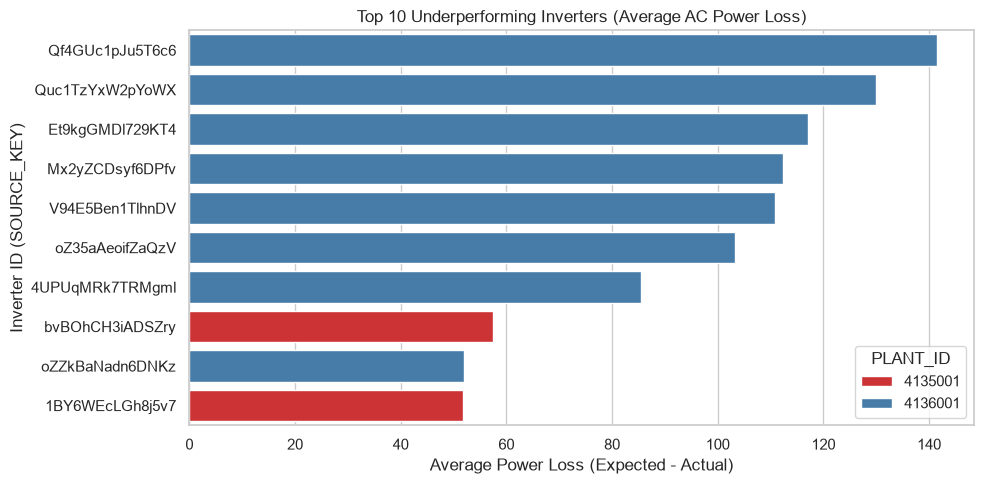

In [3]:
# Visual: Top 10 underperforming inverters
top10_loss = inv_loss.head(10)

plt.figure(figsize=(10, 5))
sns.barplot(data=top10_loss, x="LOSS", y="SOURCE_KEY", hue="PLANT_ID", dodge=False, palette="Set1")
plt.title("Top 10 Underperforming Inverters (Average AC Power Loss)")
plt.xlabel("Average Power Loss (Expected - Actual)")
plt.ylabel("Inverter ID (SOURCE_KEY)")
plt.tight_layout()
plt.show()


C:\Users\hp\AppData\Local\Temp\ipykernel_26072\4107624538.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=active, x="PLANT_ID", y="LOSS", palette="Set2")


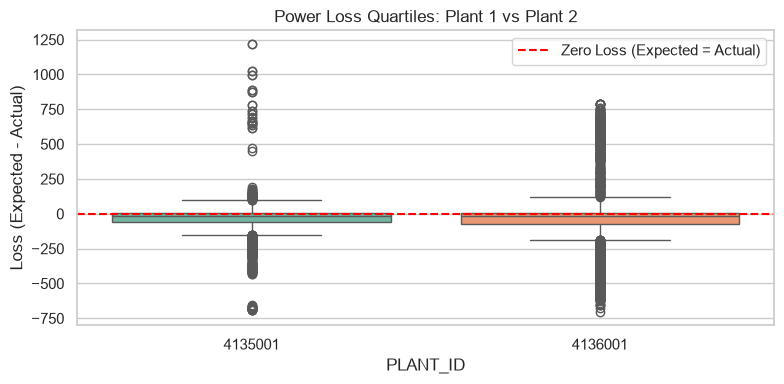

In [4]:
# Visual: Loss distribution — Plant 1 vs Plant 2
plt.figure(figsize=(8, 4))
sns.boxplot(data=active, x="PLANT_ID", y="LOSS", palette="Set2")
plt.axhline(0, color="red", linestyle="--", label="Zero Loss (Expected = Actual)")
plt.title("Power Loss Quartiles: Plant 1 vs Plant 2")
plt.ylabel("Loss (Expected - Actual)")
plt.legend()
plt.tight_layout()
plt.show()


## Part 3: What Factors Are Associated with Underperformance?
Let's check how strongly `LOSS` correlates with temperature, heat buildup (`TEMP_DIFF`), humidity, clouds, and wind.

Correlation with Power Loss:
AMBIENT_TEMPERATURE     0.027
cloud_cover             0.015
relative_humidity_2m   -0.013
wind_speed_10m         -0.022
MODULE_TEMPERATURE     -0.049
TEMP_DIFF              -0.069
IRRADIATION            -0.077
Name: LOSS, dtype: float64


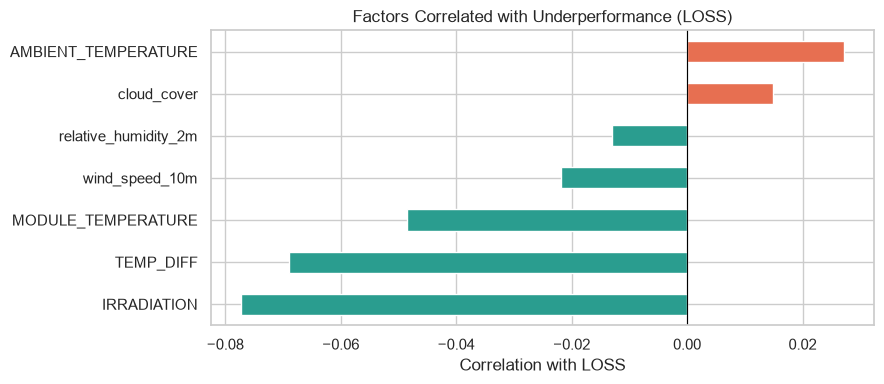

In [5]:
loss_factors = [
    "IRRADIATION", "MODULE_TEMPERATURE", "AMBIENT_TEMPERATURE", "TEMP_DIFF",
    "relative_humidity_2m", "cloud_cover", "wind_speed_10m"
]

loss_corr = active[loss_factors + ["LOSS"]].corr()["LOSS"].drop("LOSS").sort_values(ascending=False)
print("Correlation with Power Loss:")
print(loss_corr.round(3))

plt.figure(figsize=(9, 4))
loss_corr.plot(kind="barh", color=["#e76f51" if v > 0 else "#2a9d8f" for v in loss_corr])
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Factors Correlated with Underperformance (LOSS)")
plt.xlabel("Correlation with LOSS")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


## Part 4: Future Prediction — Tomorrow's Hourly Solar Forecast
Now we fetch **tomorrow's live hourly weather forecast** from the free **Open-Meteo Forecast API** (`12.97°N, 77.59°E`) and feed it into our saved model!

In [6]:
url = (
    "https://api.open-meteo.com/v1/forecast"
    "?latitude=12.97&longitude=77.59"
    "&hourly=temperature_2m,relative_humidity_2m,cloud_cover,wind_speed_10m,shortwave_radiation"
    "&forecast_days=2&timezone=Asia/Kolkata"
)

data = requests.get(url, timeout=15).json()
forecast = pd.DataFrame(data["hourly"])
forecast["DATE_TIME"] = pd.to_datetime(forecast["time"])

# Keep ONLY tomorrow (next full 24-hour day)
tomorrow_date = forecast["DATE_TIME"].dt.date.unique()[1]
tomorrow = forecast[forecast["DATE_TIME"].dt.date == tomorrow_date].copy()

print("Forecast date (Tomorrow):", tomorrow_date)
tomorrow[tomorrow["shortwave_radiation"] > 0][["DATE_TIME", "shortwave_radiation", "temperature_2m", "cloud_cover", "wind_speed_10m"]].head(8)


Forecast date (Tomorrow): 2026-11-25


,DATE_TIME,shortwave_radiation,temperature_2m,cloud_cover,wind_speed_10m
30,2026-11-25 06:00:00,1.0,20.3,100,7.6
31,2026-11-25 07:00:00,58.0,20.9,99,9.7
32,2026-11-25 08:00:00,209.0,22.4,100,10.5
33,2026-11-25 09:00:00,388.0,24.0,94,10.7
34,2026-11-25 10:00:00,581.0,25.0,93,9.2
35,2026-11-25 11:00:00,655.0,25.8,73,5.9
36,2026-11-25 12:00:00,766.0,27.0,100,5.6
37,2026-11-25 13:00:00,478.0,27.3,100,3.3


In [7]:
# Prepare the exact same 9 features our model expects
tomorrow["IRRADIATION"]         = tomorrow["shortwave_radiation"] / 1000.0
tomorrow["AMBIENT_TEMPERATURE"] = tomorrow["temperature_2m"]
tomorrow["MODULE_TEMPERATURE"]  = tomorrow["temperature_2m"] + 0.025 * tomorrow["shortwave_radiation"]
tomorrow["TEMP_DIFF"]           = tomorrow["MODULE_TEMPERATURE"] - tomorrow["AMBIENT_TEMPERATURE"]

hour = tomorrow["DATE_TIME"].dt.hour
tomorrow["HOUR_SIN"] = np.sin(2 * np.pi * hour / 24)
tomorrow["HOUR_COS"] = np.cos(2 * np.pi * hour / 24)

# Predict expected AC_POWER (force 0 when irradiation < 0.05)
preds = np.clip(model.predict(tomorrow[features].astype(np.float32)), 0, None)
tomorrow["PREDICTED_AC_POWER"] = np.where(tomorrow["IRRADIATION"] >= 0.05, preds, 0.0)

print(f"Tomorrow ({tomorrow_date}) Predicted Peak AC Power:  {tomorrow['PREDICTED_AC_POWER'].max():.1f}")
print(f"Tomorrow ({tomorrow_date}) Predicted Total Hourly Sum: {tomorrow['PREDICTED_AC_POWER'].sum():.1f}")


Tomorrow (2026-11-25) Predicted Peak AC Power:  1008.0
Tomorrow (2026-11-25) Predicted Total Hourly Sum: 5727.8


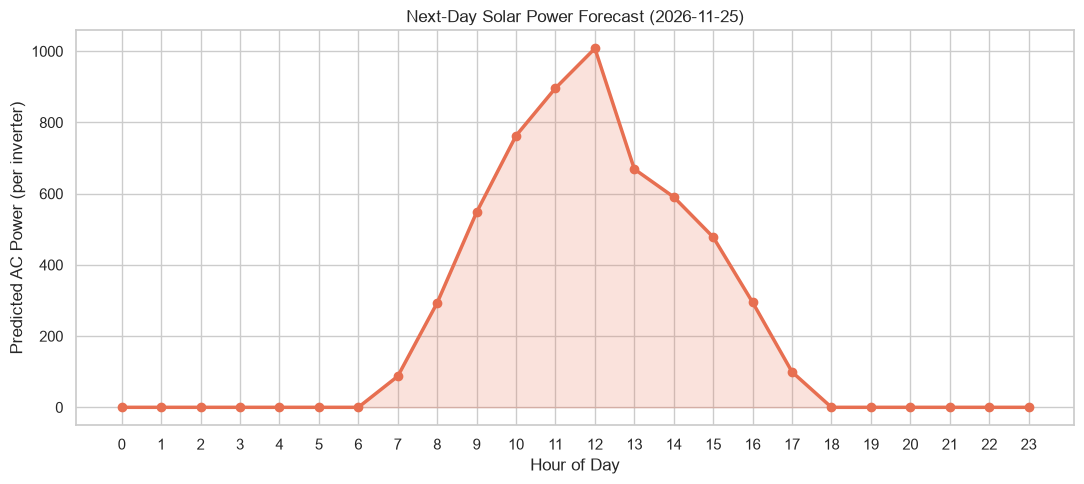

In [8]:
# Plot Tomorrow's Predicted Hourly Solar Production Curve
plt.figure(figsize=(11, 5))
plt.plot(tomorrow["DATE_TIME"].dt.hour, tomorrow["PREDICTED_AC_POWER"], marker="o", linewidth=2.5, color="#e76f51")
plt.fill_between(tomorrow["DATE_TIME"].dt.hour, tomorrow["PREDICTED_AC_POWER"], alpha=0.2, color="#e76f51")
plt.title(f"Next-Day Solar Power Forecast ({tomorrow_date})")
plt.xlabel("Hour of Day")
plt.ylabel("Predicted AC Power (per inverter)")
plt.xticks(range(0, 24))
plt.tight_layout()
plt.show()
